   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-nu

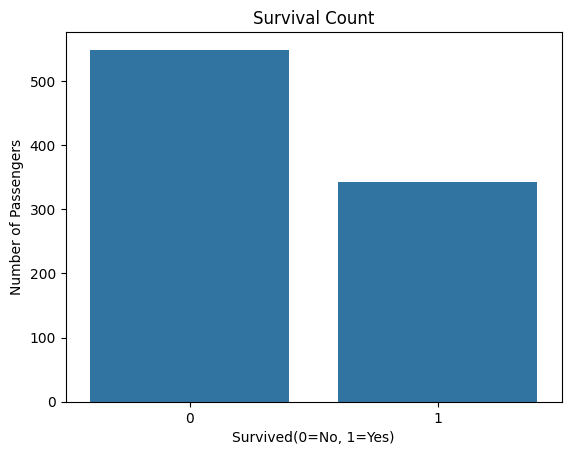

   pclass  sex   age     fare
0       3    0  22.0   7.2500
1       1    1  38.0  71.2833
2       3    1  26.0   7.9250
3       1    1  35.0  53.1000
4       3    0  35.0   8.0500
0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64
X_train: (712, 4)
X_test: (179, 4)
y_train: (712,)
y_test: (179,)
Coefficient: [[-9.96364826e-01  2.46563064e+00 -2.51645337e-02  1.18224793e-03]]
Intercept: [1.50122817]
Prediction: [0 0 0 1 1 1 1 0 1 1 0 0 1 0 0 1 0 1 0 0 0 0 1 0 0 0 0 0 0 1 0 1 0 1 0 0 0
 1 1 0 0 0 0 0 0 0 0 0 0 0 1 1 0 1 0 1 0 1 1 1 0 1 1 0 0 1 0 0 0 1 1 1 0 1
 0 0 1 1 1 0 0 1 1 0 0 0 1 1 0 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0 0 1 0 0 0 1
 0 1 0 1 0 0 0 1 0 0 1 1 0 0 0 1 0 1 0 1 0 0 1 0 1 1 0 0 1 0 1 0 0 1 1 0 0
 1 0 0 0 0 1 0 0 0 1 1 1 0 0 0 1 0 0 0 1 0 0 1 1 0 1 0 0 1 1 1]
Actual: [1 0 0 1 1 1 1 0 1 1 0 0 0 0 0 1 1 1 0 0 0 1 1 0 0 0 0 1 0 0 0 1 0 0 1 0 1
 1 1 0 0 0 0 0 0 0 0 0 0 0 1 1 0 1 0 1 0 1 1 1 0 1 1 0 0 0 0 0 0 1 0 1 1 1
 0 0 0 1 0 0 0 1 1 0 0 0 1 1 0 0 1 0 0 0 0 0 1 1 1 

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score

df = sns.load_dataset("titanic")
print(df.head())
df.info()
df["age"] = df["age"].fillna(df["age"].median())
print(df.isnull().sum())
df["sex"] = df["sex"].map({"male": 0, "female": 1})
print(df[["sex"]].head())
print(df.describe())
sns.countplot(x="survived", data=df)
plt.title("Survival Count")
plt.xlabel("Survived(0=No, 1=Yes)")
plt.ylabel("Number of Passengers")
plt.show()

X = df[["pclass", "sex", "age", "fare"]]
y = df["survived"]
print(X.head())
print(y.head())
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

model = LogisticRegression()
model.fit(X_train, y_train)
print("Coefficient:", model.coef_)
print("Intercept:", model.intercept_)

predictions = model.predict(X_test)
print("Prediction:", predictions)
print("Actual:", y_test.values)

accuracy = accuracy_score(y_test, predictions)
cm = confusion_matrix(y_test, predictions)
precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)
f1 = f1_score(y_test, predictions)

print("Accuracy:", accuracy)
print("Confusion Matrix:", cm)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

new_passenger = [[3, 0, 25, 50]]
new_prediction = model.predict(new_passenger)
print("New Passenger Prediction:", new_prediction)

probability = model.predict_proba(new_passenger)
print("Probability:", probability)





## Conclusion

In this project, Logistic Regression was used to predict whether a passenger survived the Titanic disaster based on passenger class, gender, age, and fare.The model achieved an accuracy of approximately 80.45%, with a precision of 78.26%, recall of 72.97%, and F1 score of 75.52%.For a new passenger belonging to 3rd class, male, aged 25, and paying a fare of 50, the model predicted that the passenger would not survive, with an estimated survival probability of 11.33%.

## Limitations

This project uses a relatively simple Logistic Regression model and only four features. The Titanic dataset also contains missing and potentially useful information that was not included in the model. Therefore, the predictions should not be considered perfect.The dataset represents a historical event, so the model is mainly useful for learning machine learning concepts rather than making real-world predictions.

In [20]:
df.to_csv("titanic.csv", index=False)
print("Titanic dataset saved successfully!")
import os
print(os.listdir())

Titanic dataset saved successfully!
['.config', 'titanic.csv', 'sample_data']


In [21]:
from google.colab import files
files.download("titanic.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

AttributeError: module 'os' has no attribute 'listdirt'